In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix, roc_curve

import joblib

In [2]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
print(df.info())
print(df.describe())


Dataset Shape: (1025, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB
None
               age          sex           cp     trestbps        chol  \
count  1025.000000  1025.000000  1025.000000  1025.000000  1025.00000   
mean     54.434146     0.695610     0.9

In [7]:
print("\nMissing Values:\n", df.isnull().sum())

df.drop_duplicates(inplace=True)


outlier_cols = ['trestbps', 'chol', 'thalach', 'oldpeak']
Q1 = df[outlier_cols].quantile(0.25)
Q3 = df[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

df = df[~((df[outlier_cols] < (Q1 - 1.5 * IQR)) | 
          (df[outlier_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Shape after cleaning:", df.shape)


Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Shape after cleaning: (283, 14)


np.int64(0)

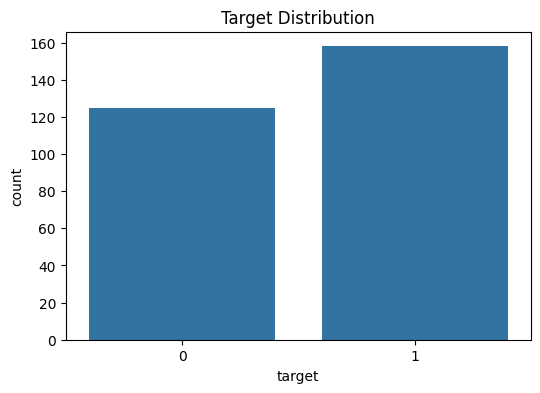

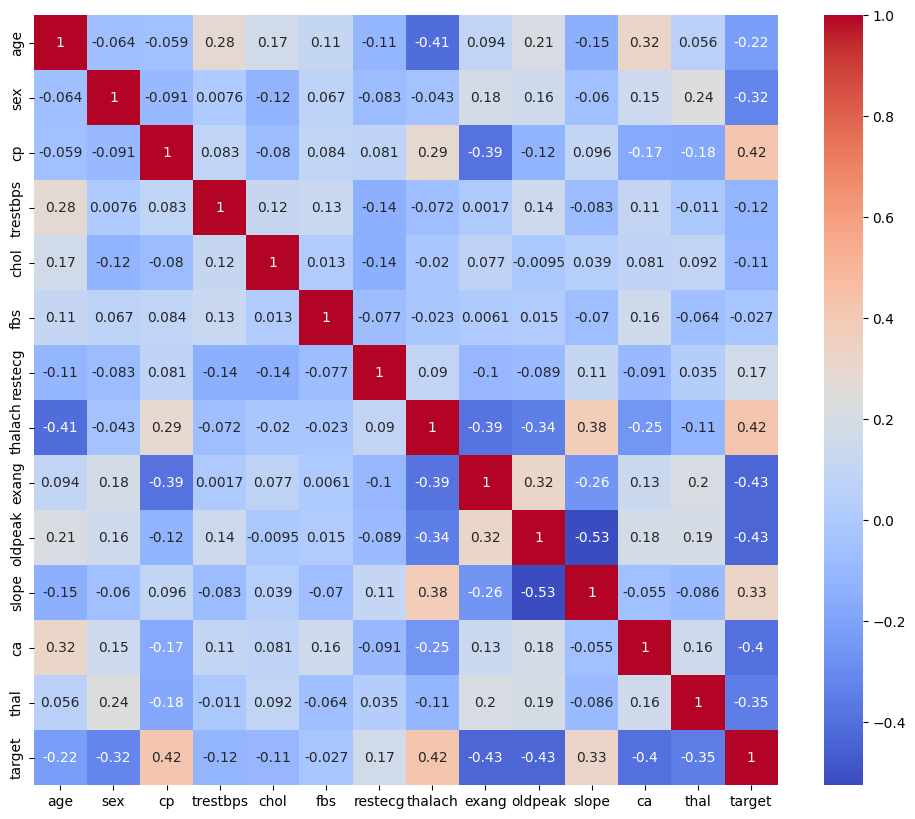

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='target', data=df)
plt.title("Target Distribution")
plt.show()

plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [15]:
df['age_group'] = pd.cut(df['age'], bins=[20,40,60,80], labels=[0,1,2]).astype(int)

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [16]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    
    "SVM": Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", SVC(probability=True, random_state=42))
    ]),
    
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    
    
}

In [17]:
results = {}

print("\n" + "="*60)
print("MODEL EVALUATION")
print("="*60)

for name, model in models.items():
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        roc = roc_auc_score(y_test, y_prob)
    else:
        roc = None

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print(f"\n{name}")
    print(f"Accuracy : {acc:.4f}")
    
    if roc is not None:
        print(f"ROC AUC  : {roc:.4f}")
    
    print(classification_report(y_test, y_pred))


MODEL EVALUATION

Logistic Regression
Accuracy : 0.8246
ROC AUC  : 0.8800
              precision    recall  f1-score   support

           0       0.83      0.76      0.79        25
           1       0.82      0.88      0.85        32

    accuracy                           0.82        57
   macro avg       0.82      0.82      0.82        57
weighted avg       0.82      0.82      0.82        57


SVM
Accuracy : 0.8246
ROC AUC  : 0.8450
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        25
           1       0.84      0.84      0.84        32

    accuracy                           0.82        57
   macro avg       0.82      0.82      0.82        57
weighted avg       0.82      0.82      0.82        57


Decision Tree
Accuracy : 0.7368
ROC AUC  : 0.7350
              precision    recall  f1-score   support

           0       0.69      0.72      0.71        25
           1       0.77      0.75      0.76        32

    accuracy   

In [18]:
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

print("\nBEST MODEL:", best_model_name)


BEST MODEL: Logistic Regression


In [19]:
cv = cross_val_score(best_model, X, y, cv=StratifiedKFold(5), scoring='accuracy')
print(f"CV Accuracy: {cv.mean():.4f} ± {cv.std():.4f}")


CV Accuracy: 0.8267 ± 0.0349


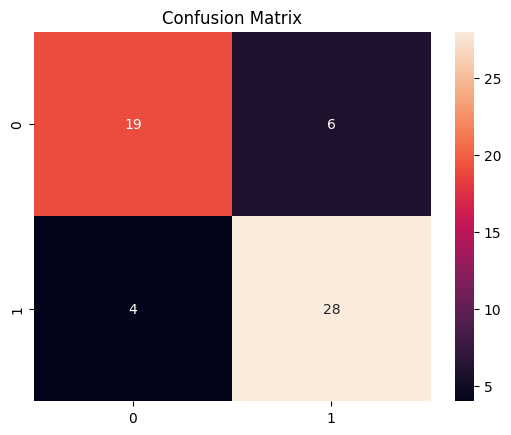

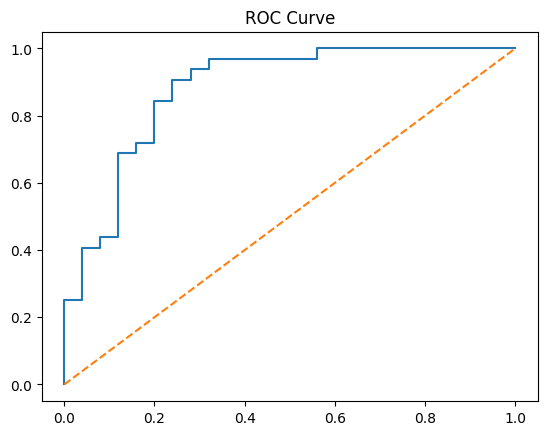

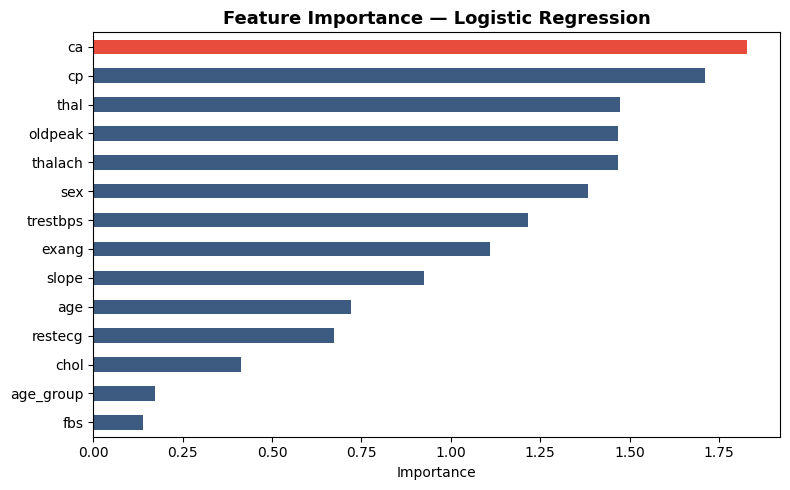

In [20]:
cm = confusion_matrix(y_test, best_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

y_prob = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.show()


try:
    importances = best_model.feature_importances_
except AttributeError:
    importances = np.abs(best_model.named_steps['model'].coef_[0])

feat_imp = pd.Series(importances, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
colors = ['#e74c3c' if v == feat_imp.max() else '#3d5a80' for v in feat_imp.values]
feat_imp.plot(kind='barh', color=colors, edgecolor='none')
plt.title(f"Feature Importance — {best_model_name}", fontsize=13, fontweight='bold')
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


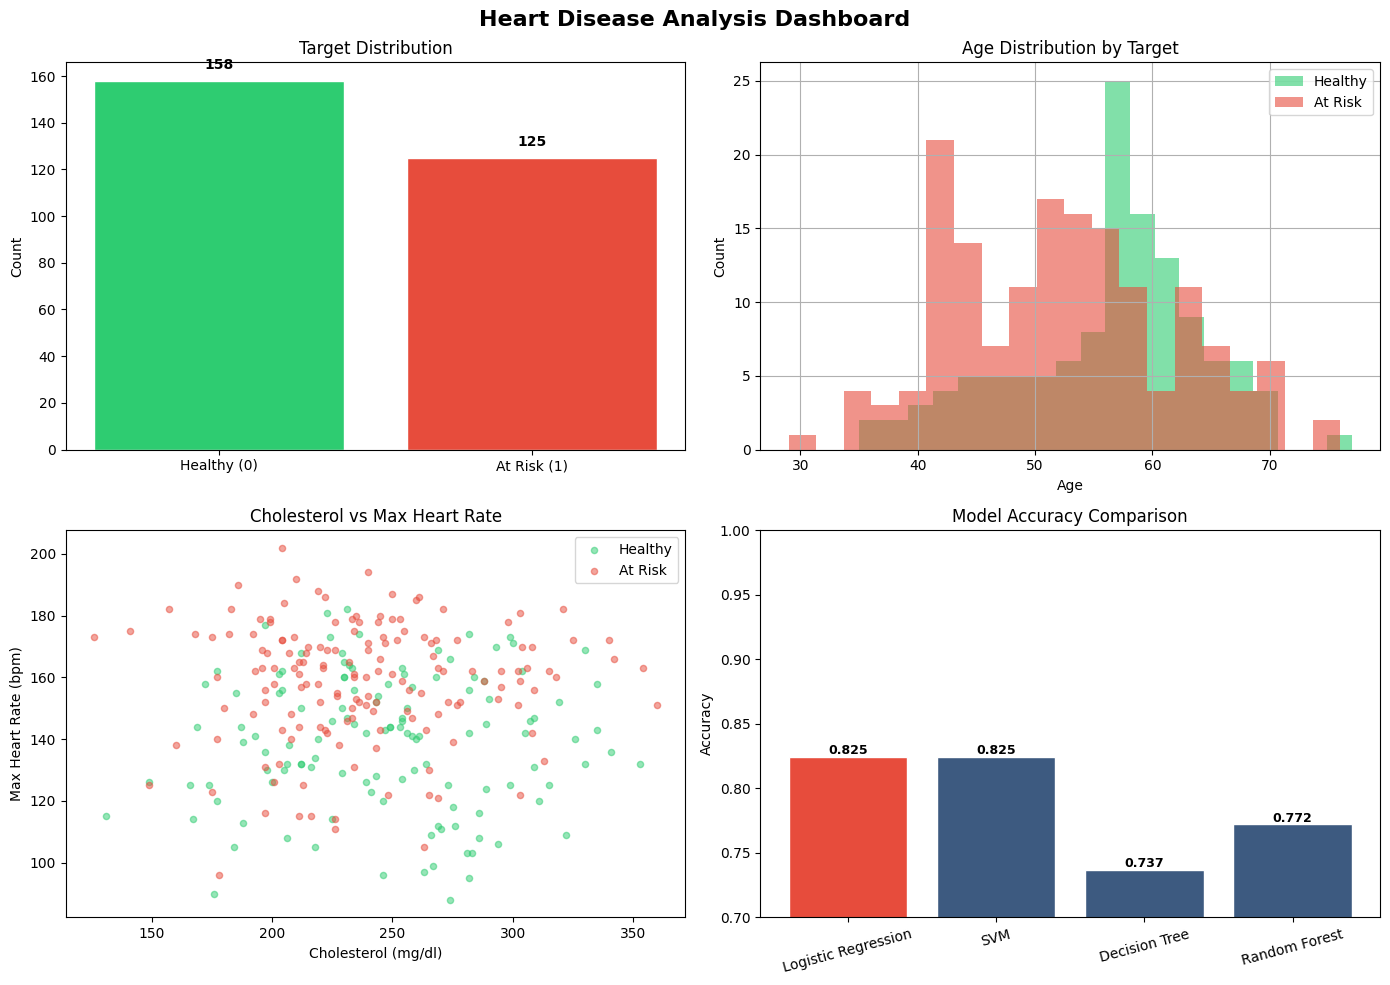


Best Model: Logistic Regression — Accuracy: 0.8246


In [21]:


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Heart Disease Analysis Dashboard', fontsize=16, fontweight='bold')


ax1 = axes[0, 0]
target_counts = df['target'].value_counts()
colors = ['#2ecc71', '#e74c3c']
ax1.bar(['Healthy (0)', 'At Risk (1)'], target_counts.values, color=colors, edgecolor='white')
ax1.set_title('Target Distribution')
ax1.set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    ax1.text(i, v + 5, str(v), ha='center', fontweight='bold')


ax2 = axes[0, 1]
df[df['target']==0]['age'].hist(ax=ax2, bins=20, alpha=0.6, color='#2ecc71', label='Healthy')
df[df['target']==1]['age'].hist(ax=ax2, bins=20, alpha=0.6, color='#e74c3c', label='At Risk')
ax2.set_title('Age Distribution by Target')
ax2.set_xlabel('Age')
ax2.set_ylabel('Count')
ax2.legend()


ax3 = axes[1, 0]
healthy = df[df['target']==0]
at_risk = df[df['target']==1]
ax3.scatter(healthy['chol'], healthy['thalach'], alpha=0.5, color='#2ecc71', label='Healthy', s=20)
ax3.scatter(at_risk['chol'],  at_risk['thalach'],  alpha=0.5, color='#e74c3c', label='At Risk',  s=20)
ax3.set_title('Cholesterol vs Max Heart Rate')
ax3.set_xlabel('Cholesterol (mg/dl)')
ax3.set_ylabel('Max Heart Rate (bpm)')
ax3.legend()

ax4 = axes[1, 1]
model_names = list(results.keys())
model_accs  = list(results.values())
bar_colors  = ['#e74c3c' if n == best_model_name else '#3d5a80' for n in model_names]
bars = ax4.bar(model_names, model_accs, color=bar_colors, edgecolor='white')
ax4.set_title('Model Accuracy Comparison')
ax4.set_ylabel('Accuracy')
ax4.set_ylim(0.7, 1.0)
ax4.tick_params(axis='x', rotation=15)
for bar, acc in zip(bars, model_accs):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{acc:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'\nBest Model: {best_model_name} — Accuracy: {max(model_accs):.4f}')


In [22]:
joblib.dump(best_model, "model.pkl")
joblib.dump(X.columns.tolist(), "columns.pkl")

print("Model saved successfully!")

Model saved successfully!


In [23]:
new_patient = {
    'age': 52, 'sex': 1, 'cp': 2, 'trestbps': 130, 'chol': 250,
    'fbs': 0, 'restecg': 1, 'thalach': 170, 'exang': 0,
    'oldpeak': 1.2, 'slope': 2, 'ca': 0, 'thal': 2
}

new_df = pd.DataFrame([new_patient])

new_df['age_group'] = pd.cut(new_df['age'], bins=[20,40,60,80], labels=[0,1,2]).astype(int)

prediction = best_model.predict(new_df)
probability = best_model.predict_proba(new_df)[:, 1]

print("\nPrediction:", "Heart Disease" if prediction[0] else "Healthy")
print(f"Probability: {probability[0]:.2%}")


Prediction: Heart Disease
Probability: 86.27%
